In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from utils import clean_text

In [2]:
ds = load_dataset(
    "uitnlp/vietnamese_students_feedback",
    revision="refs/convert/parquet",
)
print(ds)

DatasetDict({
    train: Dataset({
        features: ['sentence', 'sentiment', 'topic'],
        num_rows: 11426
    })
    validation: Dataset({
        features: ['sentence', 'sentiment', 'topic'],
        num_rows: 1583
    })
    test: Dataset({
        features: ['sentence', 'sentiment', 'topic'],
        num_rows: 3166
    })
})


In [3]:
train = ds["train"].to_pandas()
val = ds["validation"].to_pandas()
test = ds["test"].to_pandas()
train.head()

,sentence,sentiment,topic
0,slide giáo trình đầy đủ .,2,1
1,"nhiệt tình giảng dạy , gần gũi với sinh viên .",2,0
2,đi học đầy đủ full điểm chuyên cần .,0,1
3,chưa áp dụng công nghệ thông tin và các thiết ...,0,0
4,"thầy giảng bài hay , có nhiều bài tập ví dụ ng...",2,0


In [4]:
print("Số dòng train/val/test:", len(train), len(val), len(test))
train.info()
print(train.isnull().sum())

Số dòng train/val/test: 11426 1583 3166
<class 'pandas.DataFrame'>
RangeIndex: 11426 entries, 0 to 11425
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   sentence   11426 non-null  str  
 1   sentiment  11426 non-null  int64
 2   topic      11426 non-null  int64
dtypes: int64(2), str(1)
memory usage: 1.1 MB
sentence     0
sentiment    0
topic        0
dtype: int64


sentiment
Tích cực      5643
Tiêu cực      5325
Trung tính     458
Name: count, dtype: int64


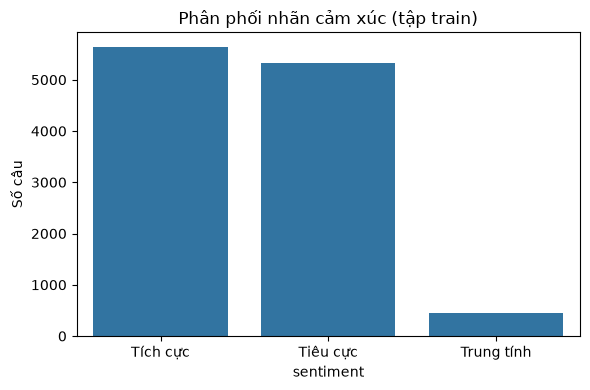

In [5]:
nhan = {0: "Tiêu cực", 1: "Trung tính", 2: "Tích cực"}
dem = train["sentiment"].map(nhan).value_counts()
print(dem)

plt.figure(figsize=(6, 4))
sns.barplot(x=dem.index, y=dem.values)
plt.title("Phân phối nhãn cảm xúc (tập train)")
plt.ylabel("Số câu")
plt.tight_layout()
plt.savefig("phan_phoi_nhan.png", dpi=200)
plt.show()

count    11426.000000
mean        14.308769
std         10.089727
min          2.000000
25%          8.000000
50%         11.000000
75%         17.000000
max        159.000000
Name: so_tu, dtype: float64


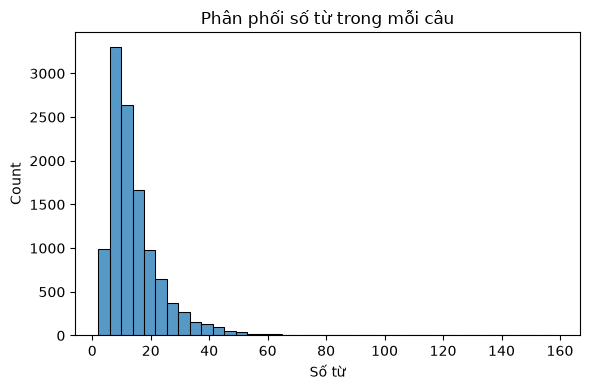

In [6]:
train["so_tu"] = train["sentence"].str.split().str.len()
print(train["so_tu"].describe())

plt.figure(figsize=(6, 4))
sns.histplot(train["so_tu"], bins=40)
plt.title("Phân phối số từ trong mỗi câu")
plt.xlabel("Số từ")
plt.tight_layout()
plt.savefig("do_dai_cau.png", dpi=200)
plt.show()

In [7]:
train["clean"] = train["sentence"].apply(clean_text)
val["clean"] = val["sentence"].apply(clean_text)
test["clean"] = test["sentence"].apply(clean_text)

for i in range(3):
    print("Gốc :", train["sentence"][i])
    print("Sạch:", train["clean"][i])
    print()

Gốc : slide giáo trình đầy đủ .
Sạch: slide giáo_trình đầy_đủ

Gốc : nhiệt tình giảng dạy , gần gũi với sinh viên .
Sạch: nhiệt_tình giảng_dạy gần_gũi với sinh_viên

Gốc : đi học đầy đủ full điểm chuyên cần .
Sạch: đi học đầy_đủ full_điểm chuyên cần



In [8]:
y_train = train["sentiment"]
y_val = val["sentiment"]
y_test = test["sentiment"]

In [9]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

bow = CountVectorizer()
Xtr_bow = bow.fit_transform(train["clean"])   # fit chỉ trên train
Xva_bow = bow.transform(val["clean"])
Xte_bow = bow.transform(test["clean"])

tfidf = TfidfVectorizer()
Xtr_tfidf = tfidf.fit_transform(train["clean"])
Xva_tfidf = tfidf.transform(val["clean"])
Xte_tfidf = tfidf.transform(test["clean"])

print("BoW:", Xtr_bow.shape)
print("TF-IDF:", Xtr_tfidf.shape)

BoW: (11426, 3796)
TF-IDF: (11426, 3796)


In [10]:
from sentence_transformers import SentenceTransformer

st_model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")
Xtr_emb = st_model.encode(train["sentence"].tolist(), show_progress_bar=True)
Xva_emb = st_model.encode(val["sentence"].tolist(), show_progress_bar=True)
Xte_emb = st_model.encode(test["sentence"].tolist(), show_progress_bar=True)

np.save("Xtr_emb.npy", Xtr_emb)
np.save("Xva_emb.npy", Xva_emb)
np.save("Xte_emb.npy", Xte_emb)
print(Xtr_emb.shape)

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

... (7 outputs left out)

Batches:   0%|          | 0/358 [00:00<?, ?it/s]

Batches:   0%|          | 0/50 [00:00<?, ?it/s]

Batches:   0%|          | 0/99 [00:00<?, ?it/s]

(11426, 384)


In [11]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

features = {
    "BoW": (Xtr_bow, Xva_bow, Xte_bow),
    "TF-IDF": (Xtr_tfidf, Xva_tfidf, Xte_tfidf),
    "Embedding": (Xtr_emb, Xva_emb, Xte_emb),
}

def tao_models(ten_feat):
    # MultinomialNB không nhận số âm, embedding có số âm nên dùng GaussianNB
    nb = GaussianNB() if ten_feat == "Embedding" else MultinomialNB()
    return {
        "KNN": KNeighborsClassifier(n_neighbors=5, metric="cosine", algorithm="brute"),
        "Naive Bayes": nb,
        "SVM": LinearSVC(),
        "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    }

rows = []
preds = {}
for ten_feat, (Xtr, Xva, Xte) in features.items():
    for ten_model, model in tao_models(ten_feat).items():
        model.fit(Xtr, y_train)
        p_val = model.predict(Xva)
        p_test = model.predict(Xte)
        rows.append({
            "Features": ten_feat,
            "Model": ten_model,
            "F1_val": f1_score(y_val, p_val, average="macro"),
            "Accuracy": accuracy_score(y_test, p_test),
            "Precision": precision_score(y_test, p_test, average="macro", zero_division=0),
            "Recall": recall_score(y_test, p_test, average="macro"),
            "F1_test": f1_score(y_test, p_test, average="macro"),
        })
        preds[(ten_feat, ten_model)] = p_test
        print("Xong:", ten_feat, "-", ten_model)

results = pd.DataFrame(rows).round(4)
results.to_csv("ket_qua.csv", index=False)
results

Xong: BoW - KNN
Xong: BoW - Naive Bayes
Xong: BoW - SVM
Xong: BoW - Random Forest
Xong: TF-IDF - KNN
Xong: TF-IDF - Naive Bayes
Xong: TF-IDF - SVM
Xong: TF-IDF - Random Forest
Xong: Embedding - KNN
Xong: Embedding - Naive Bayes
Xong: Embedding - SVM
Xong: Embedding - Random Forest


,Features,Model,F1_val,Accuracy,Precision,Recall,F1_test
0,BoW,KNN,0.6756,0.8316,0.6678,0.6393,0.6485
1,BoW,Naive Bayes,0.6397,0.8541,0.7556,0.6110,0.6034
2,BoW,SVM,0.7091,0.8765,0.7386,0.6860,0.7018
3,BoW,Random Forest,0.7052,0.8749,0.7252,0.6717,0.6846
4,TF-IDF,KNN,0.6647,0.8149,0.6717,0.6308,0.6433
5,TF-IDF,Naive Bayes,0.5952,0.8471,0.5661,0.5977,0.5800
6,TF-IDF,SVM,0.7074,0.8888,0.7832,0.6742,0.6911
7,TF-IDF,Random Forest,0.6859,0.8765,0.8197,0.6514,0.6639
8,Embedding,KNN,0.6987,0.8740,0.7765,0.6718,0.6924
9,Embedding,Naive Bayes,0.6257,0.7533,0.6442,0.7003,0.6320


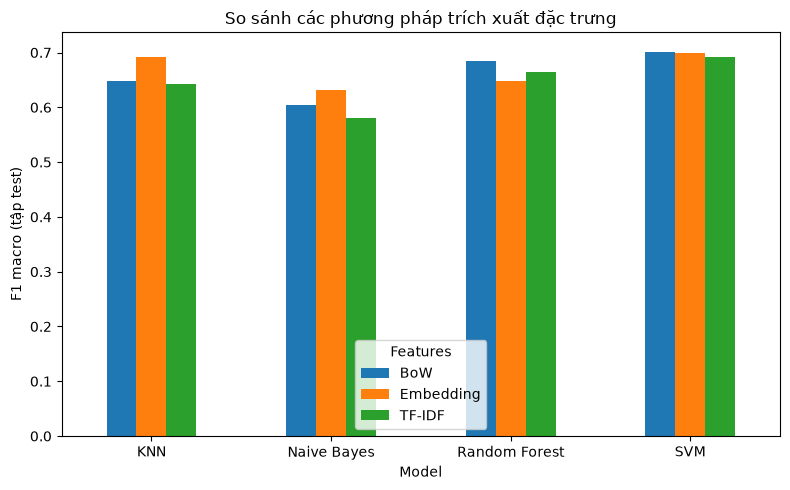

In [12]:
pivot = results.pivot(index="Model", columns="Features", values="F1_test")
pivot.plot(kind="bar", figsize=(8, 5))
plt.ylabel("F1 macro (tập test)")
plt.title("So sánh các phương pháp trích xuất đặc trưng")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("so_sanh_f1.png", dpi=200)
plt.show()

Tốt nhất: Embedding + SVM


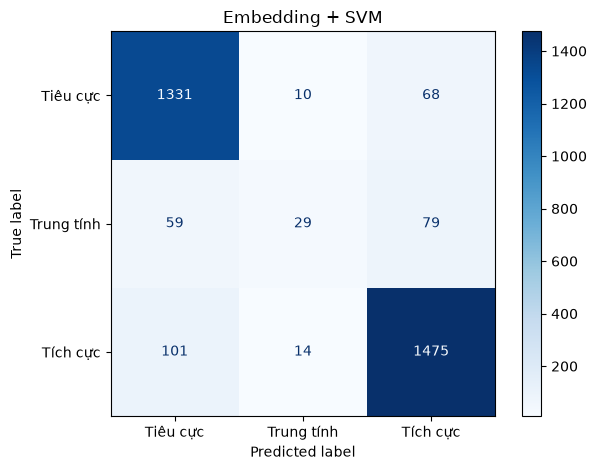

              precision    recall  f1-score   support

    Tiêu cực       0.89      0.94      0.92      1409
  Trung tính       0.55      0.17      0.26       167
    Tích cực       0.91      0.93      0.92      1590

    accuracy                           0.90      3166
   macro avg       0.78      0.68      0.70      3166
weighted avg       0.88      0.90      0.88      3166



In [13]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

best = results.sort_values("F1_val", ascending=False).iloc[0]
print("Tốt nhất:", best["Features"], "+", best["Model"])

p = preds[(best["Features"], best["Model"])]
ConfusionMatrixDisplay.from_predictions(
    y_test, p, display_labels=["Tiêu cực", "Trung tính", "Tích cực"], cmap="Blues")
plt.title(f'{best["Features"]} + {best["Model"]}')
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=200)
plt.show()

print(classification_report(y_test, p, target_names=["Tiêu cực", "Trung tính", "Tích cực"]))

In [14]:
import joblib
from sklearn.pipeline import make_pipeline

model = make_pipeline(TfidfVectorizer(), LinearSVC())
model.fit(train["clean"], y_train)
print("Accuracy test:", model.score(test["clean"], y_test))
joblib.dump(model, "model.pkl")

Accuracy test: 0.8888186986734049


['model.pkl']